In [26]:
import numpy as np
from astropy.table import Table

import matplotlib.pyplot as plt

In [3]:
lasairWHosts = Table.read("/Users/leo/Projects/PHYS367/lasair_for_alerce_top100k.csv")

In [4]:
lasairWHosts

diaObjectId,ra,decl,nDiaSources,firstDiaSourceMjdTai,lastDiaSourceMjdTai,latest_psfFlux,classification,raDeg,decDeg,separationArcsec,physical_separation_kpc,z,photoZ,catalogue_table_name
int64,float64,float64,int64,float64,float64,float64,str7,float64,float64,float64,float64,float64,float64,str27
170019695480537105,51.92833859117441,-29.044807822846288,18,61088.09394479483,61358.2735872061,-5632.93,VS,51.92833438731486,-29.044806778995714,0.323,--,--,--,DESI/GAIA
170019695496790075,53.024724407860624,-28.329677003555226,12,61088.09394479483,61358.267722652665,1352.51,SN,53.01267,-28.35858,110.866,10.361,0.004526,--,LASR
170019695754215502,54.72939259059341,-28.216583471573692,17,61088.09549981913,61358.2735872061,6391.94,AGN,54.729362732,-28.216578046,0.125,--,--,--,PS1/GAIA
170019695791439922,52.36505652980293,-27.485677674745478,18,61088.09549981913,61358.2735872061,3011.97,AGN,52.36506370474864,-27.48569061322785,0.18,--,--,--,GAIA/PS1
170019695987523894,53.50226221008056,-29.687706559060928,16,61088.09394479483,61356.284459497445,-3879.09,AGN,53.50225506272642,-29.687705140319572,0.184,1.527,1.224,--,MILLIQUAS/GAIA
170019696008495213,53.16975409716574,-29.185678374698806,13,61088.09394479483,61107.029563106844,6272.85,SN,53.170072652,-29.186048314,1.687,--,--,--,PS1/DESI
170019696009019440,53.06013382866815,-29.284937414310587,24,61088.09394479483,61358.2735872061,4614.0,VS,53.060129540620046,-29.284930597485875,0.101,--,--,--,DESI/GAIA
170019696011640884,53.19469873858197,-28.74241923722313,13,61088.09394479483,61107.029563106844,6689.68,SN,53.194521598,-28.742323016,0.648,--,--,--,DESI/PS1
170019696019505964,51.64093186559732,-29.212891863663952,21,61088.09394479483,61358.267722652665,2548.34,VS,51.64093804171613,-29.21289659991751,0.082,--,--,--,DESI


In [5]:
alerceProbs = Table.read("/Users/leo/Projects/PHYS367/alerce/alerce_probs_forTop100k_ndiasourcesGrt10_19Nov26.fits")

In [7]:
alerceProbs

oid,sid,classifier_id,classifier_version,class_id,probability,ranking,lastmjd
,,,,,,,d
int64,int16,int16,int16,int16,float32,int16,float64
170019696274833525,1,3,202,3,0.0048238095,5,61088.098045202045
170019696274833525,1,3,202,2,0.0053112437,4,61088.098045202045
170019696274833525,1,3,202,1,0.027847277,3,61088.098045202045
170019696274833525,1,3,202,4,0.17301545,2,61088.098045202045
170019696274833525,1,3,202,0,0.78900224,1,61088.098045202045
170019696274833525,1,1,201,2,0.00264938,5,61088.098045202045
170019696274833525,1,1,201,1,0.002931816,4,61088.098045202045
170019696274833525,1,1,201,0,0.0029801656,3,61088.098045202045


In [10]:
sharedOid = np.intersect1d(lasairWHosts["diaObjectId"].value.data,
                           alerceProbs["oid"].value.data)

In [11]:
def getProbabilities(i):
    evtClass = probs[probs["oid"] == diaObj["oid"][i]]
    evtProbs = dict()
    
    for classifier in np.unique(evtClass["classifier_id"]):
        evtProbs[classifier] = dict()
        for id in evtClass["class_id"][evtClass["classifier_id"] == classifier]:
            name = taxonomy[(taxonomy["class_id"] == id) & (taxonomy["classifier_id"] == classifier)]["class_name"]
            if len(name) == 1:
                evtProbs[classifier][name[0]] = evtClass[(evtClass["classifier_id"] == classifier) & (evtClass["class_id"] == id)]["probability"][0]
    
    return evtProbs

In [13]:
alerceProbsWide = Table.read("/Users/leo/Projects/PHYS367/alerce/alerce_lsstDiaObj_probabilities_wide.fits")

# Check for agreement
See if the brokers agree on AGN

In [24]:
oid_lasairAGN = lasairWHosts[lasairWHosts["classification"] == "AGN"]["diaObjectId"]

Text(0.5, -0.05, 'Probability of ALeRCE classifying\nthe object as an AGN')

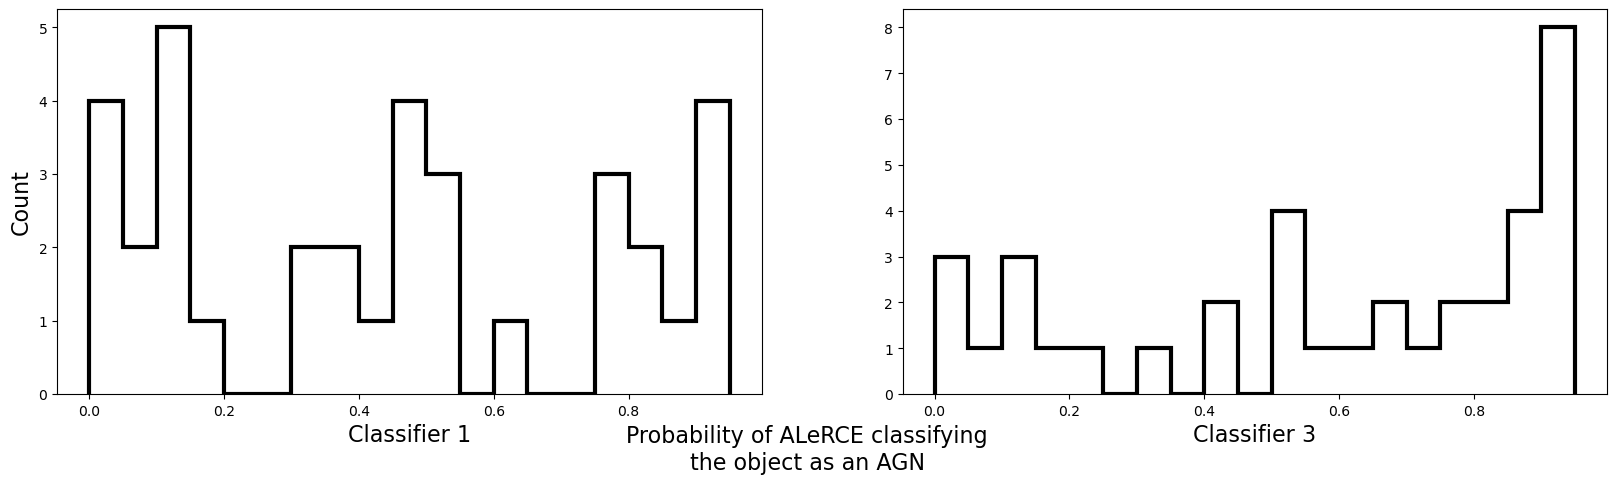

In [37]:
alerceAGN = alerceProbsWide[np.isin(alerceProbsWide["oid"], oid_lasairAGN)]
fig = plt.figure(figsize = (20, 5))
axs = fig.subplots(1, 2)

bins = np.arange(0, 1, 0.05)

axs[0].hist(alerceAGN["clf1_AGN"], bins = bins,
        histtype = "step", color = "black", linewidth = 3)
axs[1].hist(alerceAGN["clf3_AGN"], bins = bins,
        histtype = "step", color = "black", linewidth = 3)

axs[0].set_ylabel("Count", fontsize = 16)
axs[0].set_xlabel("Classifier 1", fontsize = 16)
axs[1].set_xlabel("Classifier 3", fontsize = 16)

fig.supxlabel("Probability of ALeRCE classifying\nthe object as an AGN", y = -.05, fontsize = 16)